In [33]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from collections import Counter
import csv
import hashlib
from itertools import combinations
from scipy.stats import f as f_distribution

In [4]:
from pathlib import Path

ROOT = Path.cwd()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

print("Carpeta del proyecto:", ROOT)

Carpeta del proyecto: /home/lcmj2803/coms_proyecto2


In [5]:
FIG_DIR = ROOT / "figs" / "eda"
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save_figure(fig, name):
    # PNG: imagen para documentos y presentaciones.
    fig.savefig(
        FIG_DIR / (name + ".png"),
        dpi=300,
        bbox_inches="tight"
    )

    # PDF: conserva líneas y texto como elementos vectoriales.
    fig.savefig(
        FIG_DIR / (name + ".pdf"),
        bbox_inches="tight"
    )

    print("Figura guardada: {}".format(name))


print("Carpeta de figuras:", FIG_DIR)

Carpeta de figuras: /home/lcmj2803/coms_proyecto2/figs/eda


In [6]:
ROOT= Path.cwd()
if ROOT.name =="notebooks":
    ROOT=ROOT.parent
    
DATA_DIR = ROOT / "data"

if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        "Sin carpeta:{}".format(DATA_DIR)
    )

In [7]:
MODS = (
    "BPSK", "QPSK", "8PSK",
    "16QAM", "64QAM", "16APSK"
)

CLASSES = MODS + ("ruido",)

ESN0_VALUES = tuple(range(-10,22,2))

OBS_PER_PAIR = {"train": 500, "val": 100, "test": 100}
SEEDS = {"train": 1, "val": 2, "test": 3}

META_COLUMNS = (
    "mod", "snr_db", "snr_inst_db",
    "cfo", "phase", "amp", "channel", "seed"
)

print("Leyendo datos desde:", DATA_DIR)

Leyendo datos desde: /home/lcmj2803/coms_proyecto2/data


In [8]:
datasets={}

for split in ("train","val","test"):
    folder = DATA_DIR/ split 
    
    #Acceso al archivo sin cargarlo completo de golpe en RAM 
    X = np.load(
        folder / "X.npy",
        mmap_mode="r",
        allow_pickle=False
    )
    
    with(folder/"meta.csv").open(
        "r",newline="", encoding="utf-8"
    ) as file: 
        reader = csv.DictReader(file)
        
        assert tuple(reader.fieldnames or ()) ==META_COLUMNS, (
            "{}:columnas incorrectas".format(split)
        )
        
        metadata = list(reader)
        
    #CSV devuelve textos: convertimos los campos numericos
    for row in metadata:
        for field in ("snr_db", "snr_inst_db", "cfo","phase","amp"):
            row[field] = float(row[field])
            
        row["seed"] = int(row["seed"])
        
    expected_n = len(CLASSES) * len(ESN0_VALUES) * OBS_PER_PAIR[split]
    
    assert X.shape == (expected_n, 2, 1024), (
        "{}:forma incorrecta".format(split)
    )

    assert X.dtype == np.float32, (
        "{}:tipo incorrecto".format(split)
    )
    
    assert len(metadata) == expected_n, (
        "{}: cantidad incorrecta de metadatos".format(split)
    )
    assert all(row["seed"] == SEEDS[split] for row in metadata), (
        "{}: semillas incorrectas".format(split)
    )

    # Revisamos todas las muestras en bloques para limitar la RAM.
    for start in range(0, len(X), 2048):
        block = X[start:start + 2048]

        assert np.isfinite(block).all(), (
            "{}: hay NaN o infinitos desde la observacion {}".format(
                split, start
            )
        )

    datasets[split] = {"X": X, "metadata": metadata}

    print("{}: integridad OK | forma={} | tipo={}".format(
        split, X.shape, X.dtype
    ))
    
for split, dataset in datasets.items():
    metadata = dataset["metadata"]
    n = OBS_PER_PAIR[split]

    counts = Counter(row["mod"] for row in metadata)
    expected_counts = {
        name: len(ESN0_VALUES) * n
        for name in CLASSES
    }

    assert counts == expected_counts, (
        "{}: clases desequilibradas o inesperadas".format(split)
    )

    # Revisamos cada pareja modulacion-Es/N0.
    pair_counts = Counter(
        (row["mod"], row["snr_db"])
        for row in metadata
        if row["mod"] != "ruido"
    )

    expected_pairs = {
        (mod, snr): n
        for mod in MODS
        for snr in ESN0_VALUES
    }

    assert pair_counts == expected_pairs, (
        "{}: cantidades incorrectas por pareja".format(split)
    )

    assert all(
        np.isnan(row["snr_db"])
        and np.isnan(row["snr_inst_db"])
        for row in metadata
        if row["mod"] == "ruido"
    ), "{}: el ruido debe tener Es/N0 indefinido".format(split)

    print("{}: balance OK | {} observaciones por clase".format(
        split, len(ESN0_VALUES) * n
    ))    
    
    


train: integridad OK | forma=(56000, 2, 1024) | tipo=float32
val: integridad OK | forma=(11200, 2, 1024) | tipo=float32
test: integridad OK | forma=(11200, 2, 1024) | tipo=float32
train: balance OK | 8000 observaciones por clase
val: balance OK | 1600 observaciones por clase
test: balance OK | 1600 observaciones por clase


Figura guardada: 01_balance_clases_train


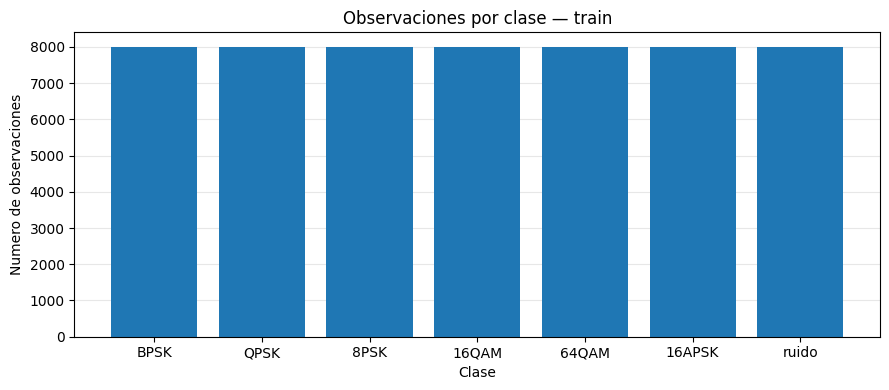

In [9]:
counts = Counter(
    row["mod"]
    for row in datasets["train"]["metadata"]
)

fig, ax = plt.subplots(figsize=(9, 4))

ax.bar(CLASSES, [counts[name] for name in CLASSES])
ax.set_title("Observaciones por clase — train")
ax.set_xlabel("Clase")
ax.set_ylabel("Numero de observaciones")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
save_figure(fig, "01_balance_clases_train")
plt.show()

In [10]:
metadata = datasets["train"]["metadata"]

counts = Counter(
    (row["mod"],row["snr_db"])
    for row in metadata
    if row["mod"] != "ruido"
)


Figura guardada: 02_balance_esn0_train


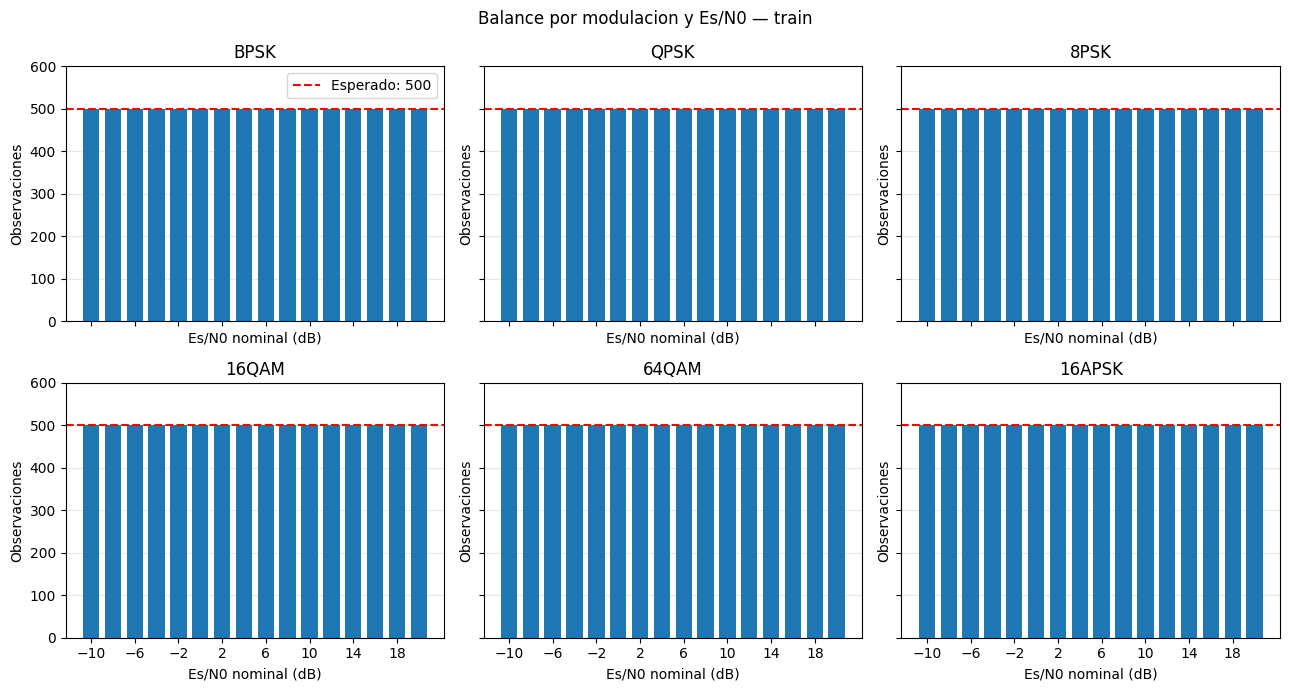

In [11]:

fig,axes = plt.subplots(2,3, figsize=(13,7), sharex=True, sharey=True)
for ax, mod in zip(axes.ravel(), MODS):
    values = [counts[(mod,snr)] for snr in ESN0_VALUES]
    
    ax.bar(ESN0_VALUES,values,width=1.5)
    ax.axhline(
        OBS_PER_PAIR["train"],
        color ="red",
        linestyle = "--",
        label="Esperado: 500"
    )
    
    ax.set_title(mod)
    ax.set_xlabel("Es/N0 nominal (dB)")
    ax.set_ylabel("Observaciones")
    ax.set_xticks(ESN0_VALUES[::2])
    ax.set_ylim(0,600)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
    
axes[0, 0].legend()
fig.suptitle("Balance por modulacion y Es/N0 — train")
plt.tight_layout()
save_figure(fig, "02_balance_esn0_train")
plt.show()

In [12]:
# Excluimos ruido porque no tiene CFO ni fase asignados.
signal_meta = [
    row for row in datasets["train"]["metadata"]
    if row["mod"] != "ruido"
]

cfo = np.array([row["cfo"] for row in signal_meta])
phase = np.array([row["phase"] for row in signal_meta])
amp = np.array([row["amp"] for row in signal_meta])



In [13]:
# Comprobamos valores finitos y rangos antes de graficar.
assert np.isfinite(cfo).all()
assert np.isfinite(phase).all()
assert np.isfinite(amp).all()

assert ((cfo >= -1e-4) & (cfo <= 1e-4)).all()
assert ((phase >= 0) & (phase < 2 * np.pi)).all()
assert ((amp >= 0.1) & (amp <= 10)).all()

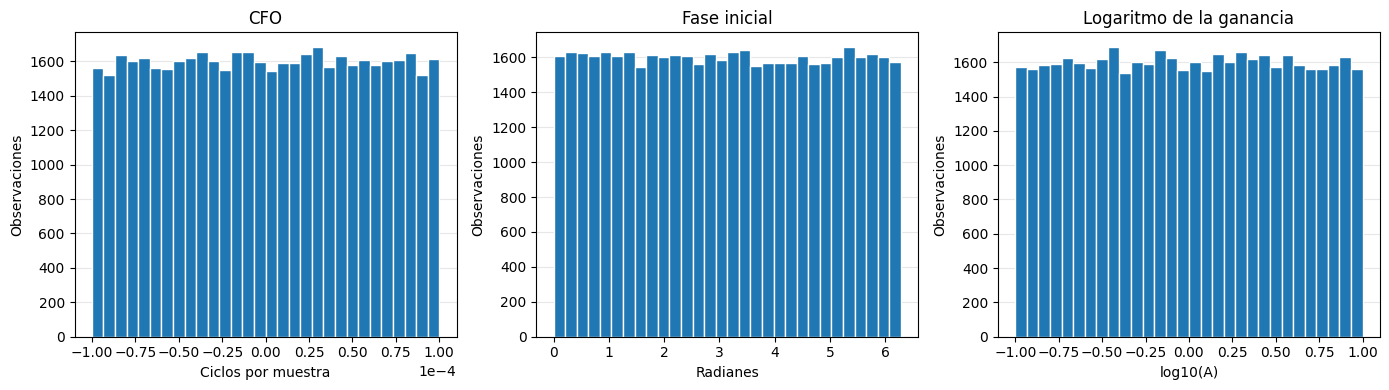

Figura guardada: 03_balance_canal_train
Parametros de las señales: valores finitos y rangos correctos.


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].hist(
    cfo, bins=30, range=(-1e-4, 1e-4), edgecolor="white"
)
axes[0].set_title("CFO")
axes[0].set_xlabel("Ciclos por muestra")
axes[0].ticklabel_format(axis="x", style="sci", scilimits=(0, 0))

axes[1].hist(
    phase, bins=30, range=(0, 2 * np.pi), edgecolor="white"
)
axes[1].set_title("Fase inicial")
axes[1].set_xlabel("Radianes")

axes[2].hist(
    np.log10(amp), bins=30, range=(-1, 1), edgecolor="white"
)
axes[2].set_title("Logaritmo de la ganancia")
axes[2].set_xlabel("log10(A)")

for ax in axes:
    ax.set_ylabel("Observaciones")
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()
save_figure(fig, "03_balance_canal_train")
print("Parametros de las señales: valores finitos y rangos correctos.")

In [15]:
hash_indexes ={}
duplicates_inside = {}

In [16]:
#Duplicados dentro de cada conjunto
for split in ("train","val","test"):
    X = datasets[split]["X"]
    seen = {}
    repeated = []
    
    for index in range(len(X)):
        fragment = X[index].tobytes(order="C")
        fingerprint = hashlib.sha256(fragment).digest()
        
        if fingerprint in seen:
            first_index = seen[fingerprint]
            
            #Confirmamos la igualdad exacta del contenido
            if fragment != X[first_index].tobytes(order="C"):
                raise RuntimeError("Colision de hash detectada")
                
            repeated.append((first_index,index))
            
        else: 
            seen[fingerprint] = index 
    
    hash_indexes[split]=seen
    duplicates_inside[split]=repeated
    
    print("{}: {} observaciones repetidas".format(
        split, len(repeated)
    ))

    if repeated:
        print("Ejemplos (indice original, repetido):", repeated[:5])

train: 0 observaciones repetidas
val: 0 observaciones repetidas
test: 0 observaciones repetidas


In [17]:
# 2. Duplicados entre conjuntos.
duplicates_between = {}

for split_a, split_b in combinations(("train", "val", "test"), 2):
    indexes_a = hash_indexes[split_a]
    indexes_b = hash_indexes[split_b]

    common = indexes_a.keys() & indexes_b.keys()
    matches = []

    for fingerprint in common:
        index_a = indexes_a[fingerprint]
        index_b = indexes_b[fingerprint]

        fragment_a = datasets[split_a]["X"][index_a].tobytes(order="C")
        fragment_b = datasets[split_b]["X"][index_b].tobytes(order="C")

        if fragment_a != fragment_b:
            raise RuntimeError("Colision de hash detectada.")

        matches.append((index_a, index_b))

    duplicates_between[(split_a, split_b)] = matches

    print("{} / {}: {} fragmentos distintos compartidos".format(
        split_a, split_b, len(matches)
    ))

    if matches:
        print("Ejemplos de indices:", matches[:5])

train / val: 0 fragmentos distintos compartidos
train / test: 0 fragmentos distintos compartidos
val / test: 0 fragmentos distintos compartidos


1024

[ 476.65927-259.4377j   144.43964-396.47076j -226.86252-474.17865j ...
  301.72894+497.4374j   696.2416 +121.55538j -201.96136 +72.68368j]
[ 0.          0.00097656  0.00195312 ... -0.00292969 -0.00195312
 -0.00097656]

Estadistico T: 135.8836


Bins dentro: 173

Bins fuera: 819

T bajo ruido: F(346, 1638)

Media teorica: 1.001222
